In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

warnings.filterwarnings('ignore')

# Modern ve temiz grafik teması
sns.set_theme(style="ticks", palette="deep")
plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.spines.top': False,
    'axes.spines.right': False
})

columns = [f'Router{i}' for i in range(1, 8)] + ['Room']
df = pd.read_csv('wifi_localization.txt', sep='\t', names=columns)

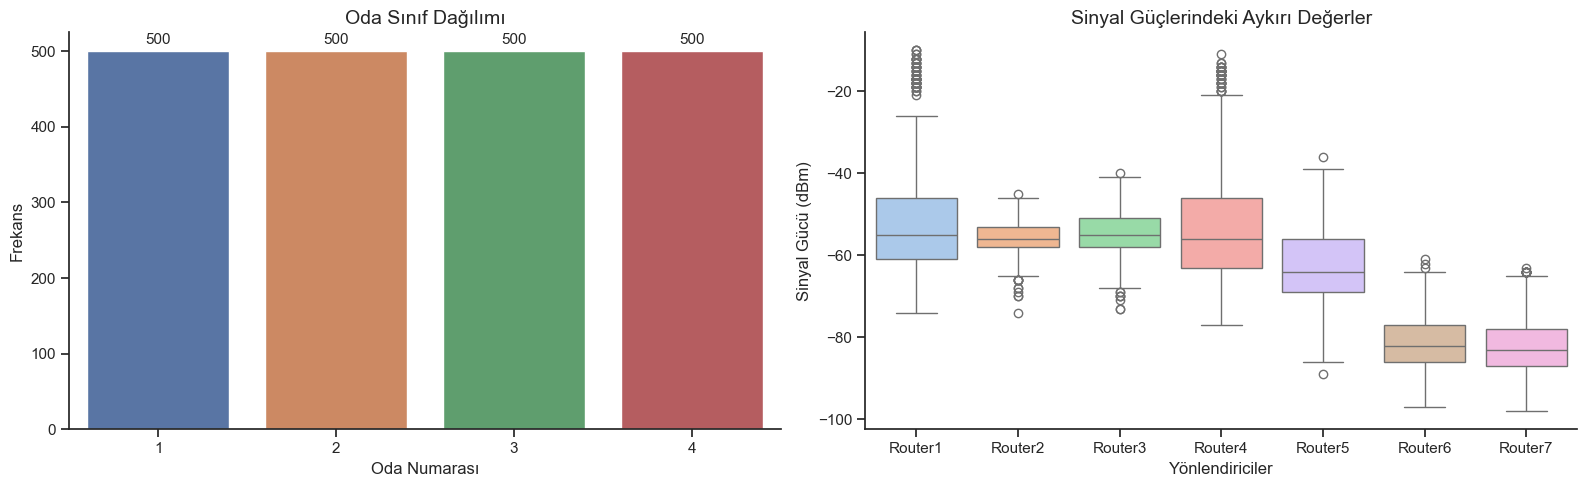

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Sınıf Dağılımı Grafiği
sns.countplot(data=df, x='Room', palette="deep", ax=axes[0])
axes[0].set_title("Oda Sınıf Dağılımı")
axes[0].set_xlabel("Oda Numarası")
axes[0].set_ylabel("Frekans")
for container in axes[0].containers:
    axes[0].bar_label(container, padding=3)

# Aykırı Değerler (Boxplot)
sns.boxplot(data=df.drop('Room', axis=1), palette="pastel", ax=axes[1])
axes[1].set_title("Sinyal Güçlerindeki Aykırı Değerler")
axes[1].set_ylabel("Sinyal Gücü (dBm)")
axes[1].set_xlabel("Yönlendiriciler")

plt.tight_layout()
plt.show()

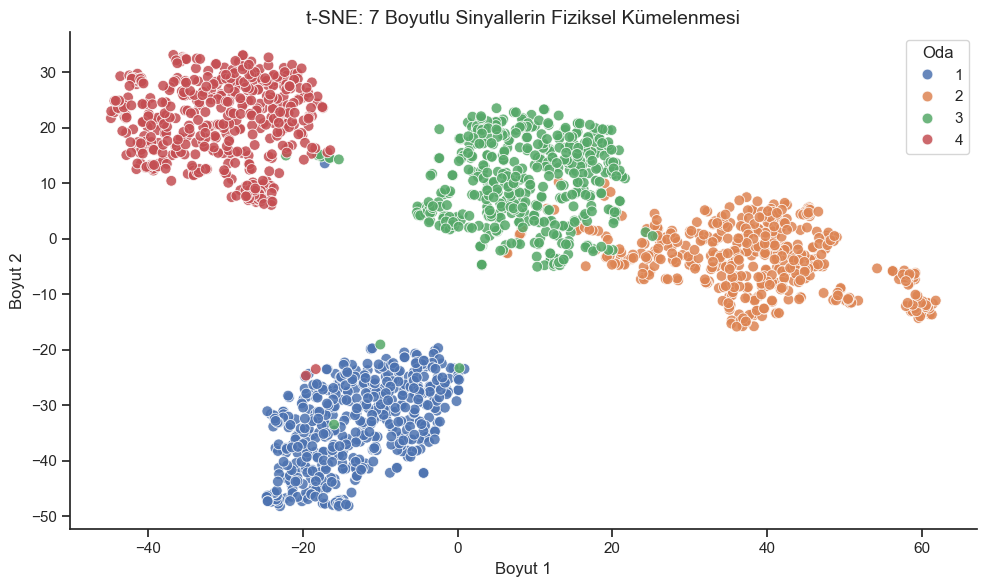

In [26]:
tsne = TSNE(n_components=2, random_state=42, perplexity=40)
X_tsne = tsne.fit_transform(df.drop('Room', axis=1))

plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=df['Room'], palette="deep", s=60, alpha=0.85)
plt.title("t-SNE: 7 Boyutlu Sinyallerin Fiziksel Kümelenmesi")
plt.xlabel("Boyut 1")
plt.ylabel("Boyut 2")
plt.legend(title="Oda")
plt.show()

In [27]:
X = df.drop('Room', axis=1)
y = df['Room']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

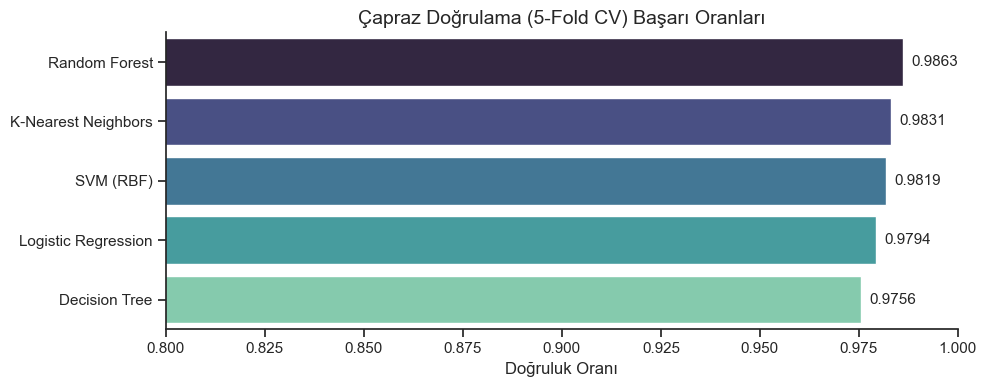

In [28]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "SVM (RBF)": SVC(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results_list = []

for name, model in models.items():
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', model)
    ])

    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='accuracy')
    results_list.append({"Model": name, "CV_Ortalama": cv_scores.mean()})

df_results = pd.DataFrame(results_list).sort_values(by="CV_Ortalama", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 4))
ax = sns.barplot(x="CV_Ortalama", y="Model", data=df_results, palette="mako")
plt.title("Çapraz Doğrulama (5-Fold CV) Başarı Oranları")
plt.xlabel("Doğruluk Oranı")
plt.ylabel("")
plt.xlim(0.8, 1.0)
for i, v in enumerate(df_results["CV_Ortalama"]):
    ax.text(v + 0.002, i, f"{v:.4f}", va='center')
plt.show()

In [29]:
best_model_name = df_results.iloc[0]["Model"]

param_grids = {
    "K-Nearest Neighbors": {
        'classifier__n_neighbors': [3, 5, 7, 9],
        'classifier__weights': ['uniform', 'distance']
    },
    "Random Forest": {
        'classifier__n_estimators': [50, 100, 200],
        'classifier__max_depth': [None, 10, 20],
        'classifier__min_samples_split': [2, 5]
    },
    "SVM (RBF)": {
        'classifier__C': [0.1, 1, 10],
        'classifier__gamma': ['scale', 'auto', 0.1]
    }
}

winner_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', models[best_model_name])
])

if best_model_name in param_grids:
    grid_search = GridSearchCV(winner_pipeline, param_grids[best_model_name], cv=cv, scoring='accuracy', n_jobs=-1)
    grid_search.fit(X_train, y_train)
    final_model = grid_search.best_estimator_

    print(f"Optimize Edilen Lider Model: {best_model_name}")
    print(f"Parametreler: {grid_search.best_params_}")
else:
    final_model = winner_pipeline
    final_model.fit(X_train, y_train)

Optimize Edilen Lider Model: Random Forest
Parametreler: {'classifier__max_depth': None, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 50}


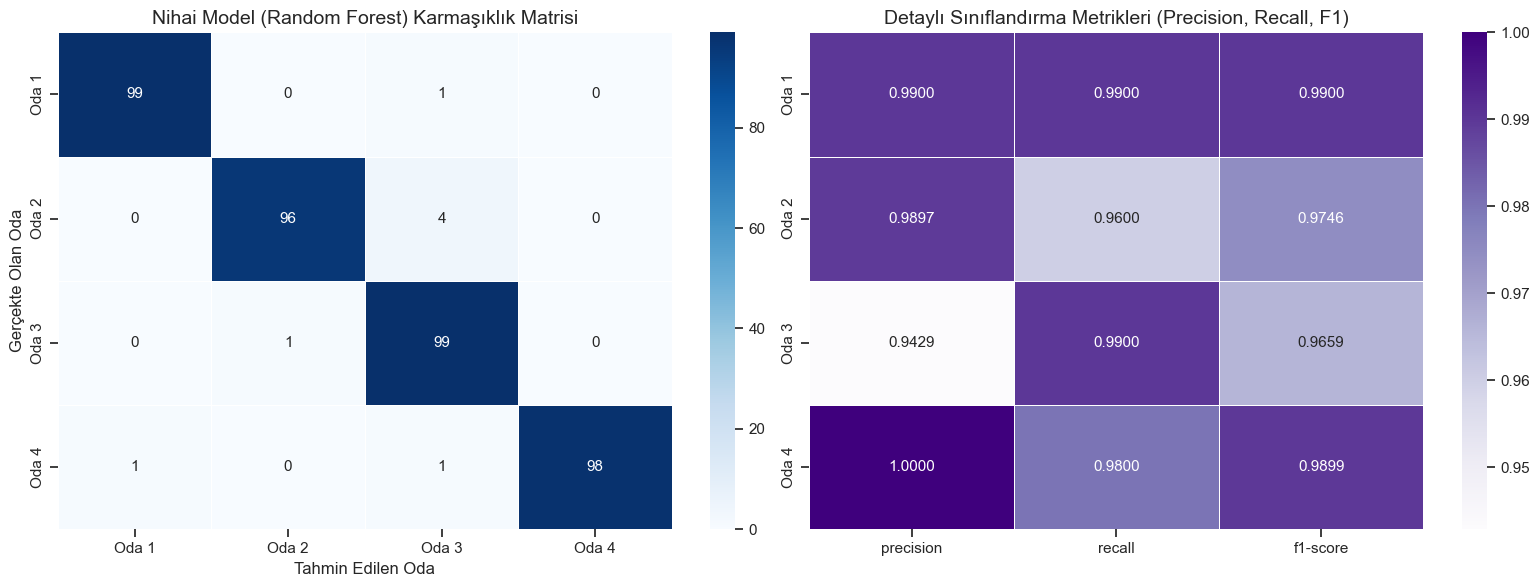

In [30]:
y_pred_final = final_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Karmaşıklık Matrisi Grafiği
cm = confusion_matrix(y_test, y_pred_final)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', linewidths=0.5,
            xticklabels=[f'Oda {i}' for i in range(1, 5)],
            yticklabels=[f'Oda {i}' for i in range(1, 5)], ax=axes[0])
axes[0].set_title(f"Nihai Model ({best_model_name}) Karmaşıklık Matrisi")
axes[0].set_xlabel("Tahmin Edilen Oda")
axes[0].set_ylabel("Gerçekte Olan Oda")

# 2. Sınıflandırma Raporu (Classification Report) Isı Haritası
report_dict = classification_report(y_test, y_pred_final, target_names=[f'Oda {i}' for i in range(1, 5)], output_dict=True)
report_df = pd.DataFrame(report_dict).iloc[:-1, :4].T
sns.heatmap(report_df, annot=True, cmap='Purples', fmt='.4f', linewidths=0.5, ax=axes[1])
axes[1].set_title("Detaylı Sınıflandırma Metrikleri (Precision, Recall, F1)")

plt.tight_layout()
plt.show()